# Incremental Structure-from-Motion with COLMAP (pycolmap 4)

Structure-from-Motion (SfM) recovers camera poses, intrinsics and a sparse 3D point cloud from
an *unordered* set of photos. It is how the camera poses for NeRF / Gaussian-splatting
datasets are made, how maps for visual relocalisation are built, and the offline cousin of
visual SLAM. This notebook runs **COLMAP's incremental pipeline through its Python bindings**
(`pycolmap` 4.2) on 32 photos of the *South Building* dataset, then swaps COLMAP's SIFT for
**DISK + LightGlue** matches imported into the COLMAP database, and finds out the hard way
why a reconstruction must be checked against something other than itself.

**What you will learn**

* the stages of incremental SfM: features → exhaustive matching → geometric verification →
  initial pair → image registration (PnP) → triangulation → bundle adjustment;
* the pycolmap 4.x API (`extract_features`, `match_exhaustive`, `incremental_mapping`,
  `Database`, `Reconstruction`; poses via `image.cam_from_world()`);
* how to read a reconstruction: registered images, points, track length, reprojection
  error, self-calibrated focal length, and its accuracy against a reference model;
* how to plug *any* matcher into COLMAP (keypoints + matches written to the database,
  with COLMAP's pixel convention);
* a classic SfM failure: **look-alike structures** (a symmetric building) produce confident,
  geometrically consistent false matches that fold the model, while registration counts and
  reprojection errors still look perfect, and what a pairing prior can (and cannot) do about it.

**Prerequisites:** notebooks 01 and 03. **Data:** `make data-09_multiview_geometry`
(South Building photos downscaled to 1024x768 + the reference model shipped with the dataset).
**Runtime:** about 4 minutes (COLMAP on CPU; DISK/LightGlue on the GPU).
The reconstructions are written to `runs/09_multiview_geometry/south_building/` for reuse in
projects 10 (feed-forward 3D) and 11 (Gaussian splatting).

## Setup

In [1]:
# --- Setup: imports, seeding, device, data/output paths, plotting style ---
import shutil
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycolmap

import cvlab.device
from cvlab import viz
from cvlab.io import outputs_dir, project_dir, read_image, repo_root, runs_dir, save_json

PROJECT = "09_multiview_geometry"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mvgeo as M  # noqa: E402

device = cvlab.device.setup(seed=0)
viz.set_style()
pycolmap.logging.minloglevel = 2  # keep COLMAP's C++ logging (warnings and below) quiet
RESULTS_DIR = project_dir(PROJECT) / "results"
IMAGE_DIR = M.south_building_dir() / "images"
OUT = runs_dir(PROJECT, "south_building", create=True)
print(f"pycolmap {pycolmap.__version__} ({pycolmap.COLMAP_version}) | CUDA build: {pycolmap.has_cuda}")
print(f"images: {IMAGE_DIR.relative_to(repo_root())} | outputs: {OUT.relative_to(repo_root())}")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
pycolmap 4.2.1 (COLMAP 4.2.1) | CUDA build: False
images: data/south_building/images | outputs: runs/09_multiview_geometry/south_building


## 1. The image set

South Building (provided with COLMAP, photos by C. Zach) has 128 photos taken while walking
around a building. We use **32 images: every second photo of the first 64**, a contiguous
half-loop with plenty of overlap between neighbours. In section 8 we stress-test the
pipelines with every fourth photo of the *full* loop (wider baselines, less overlap).

128 photos available, 32 selected: P1180141.JPG ... P1180203.JPG


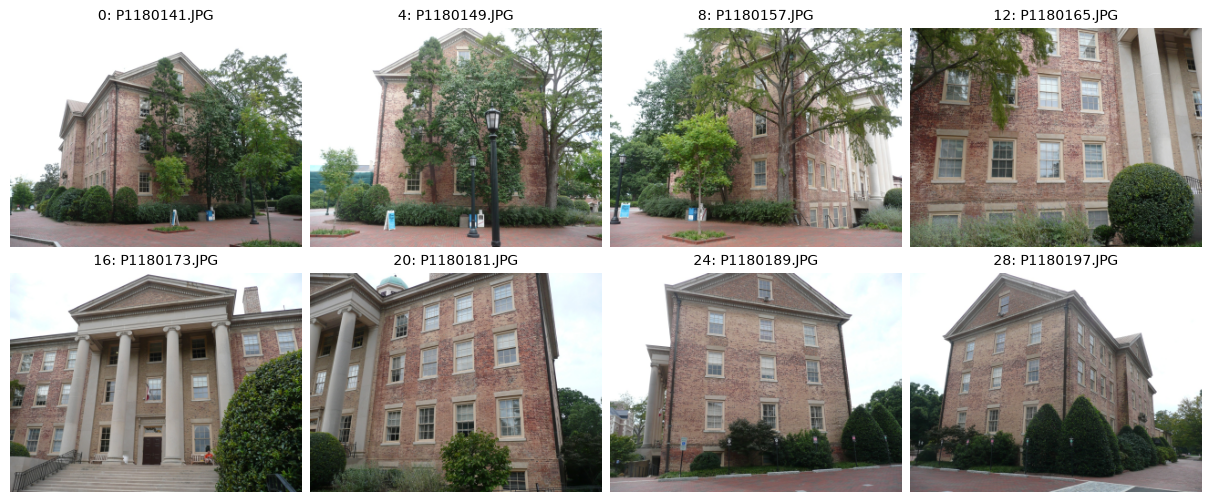

In [2]:
# --- Choose the 32-image subset and show a few of them ---
all_names = sorted(p.name for p in IMAGE_DIR.glob("*.JPG"))
names = all_names[0:64:2]
print(f"{len(all_names)} photos available, {len(names)} selected: {names[0]} ... {names[-1]}")
fig = viz.show_images([read_image(IMAGE_DIR / n, max_side=320) for n in names[::4]],
                      [f"{k * 4}: {n}" for k, n in enumerate(names[::4])], ncols=4, size=3.0)
plt.show()

## 2. Features and exhaustive matching

COLMAP extracts up to 8192 SIFT features per image (CPU here: the `pycolmap` wheel installed
in this environment is the CPU build) into an SQLite database, then matches **all**
$N(N-1)/2 = 496$ pairs (`match_exhaustive`) with a ratio test. For each pair, *geometric
verification* estimates $F$, $E$ and a homography $H$ with RANSAC and classifies the pair
(calibrated, uncalibrated, planar, panoramic...); only verified inlier matches are used by
the mapper. Because the JPEGs carry no EXIF focal length, every image starts from COLMAP's
default guess $f_0 = 1.2\max(W, H)$ and one shared SIMPLE_RADIAL camera $(f, c_x, c_y, k)$
is refined during mapping.

In [3]:
# --- SIFT extraction + exhaustive matching + verification (pycolmap 4 API) ---
sift_dir = OUT / "sift"
sift_dir.mkdir(parents=True, exist_ok=True)
db_sift = sift_dir / "database.db"
db_sift.unlink(missing_ok=True)
reader = pycolmap.ImageReaderOptions()
reader.camera_model = "SIMPLE_RADIAL"
extraction = pycolmap.FeatureExtractionOptions()
extraction.sift.max_num_features = 8192
t0 = time.perf_counter()
pycolmap.extract_features(db_sift, IMAGE_DIR, image_names=names,
                          camera_mode=pycolmap.CameraMode.SINGLE, reader_options=reader,
                          extraction_options=extraction, device=pycolmap.Device.cpu)
t_feat = time.perf_counter() - t0
t0 = time.perf_counter()
pycolmap.match_exhaustive(db_sift, device=pycolmap.Device.cpu)
t_match = time.perf_counter() - t0
db_stats_sift = M.database_stats(db_sift)
print(f"features: {t_feat:.1f} s | matching + verification: {t_match:.1f} s")
print(db_stats_sift)

features: 3.3 s | matching + verification: 11.4 s
{'num_images': 32, 'num_keypoints': 300180, 'num_matched_pairs': 496, 'num_verified_pairs': 496, 'num_matches': 50706, 'num_inlier_matches': 41447}


The **view graph** shows which image pairs share verified inlier matches. Neighbouring photos
overlap strongly (bright band near the diagonal); far-apart photos see different sides of
the building and should share nothing. (The database counts every *processed* pair as
"verified", including those whose verification failed; the matrix counts pairs with at
least one inlier.)

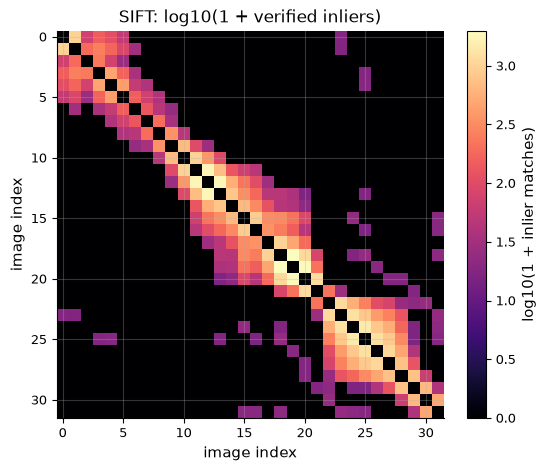

129 of 496 pairs have verified inlier matches


In [4]:
# --- View graph: verified inlier matches between every pair of images ---
G_sift = M.view_graph(db_sift, names)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(np.log10(1 + G_sift), cmap="magma")
ax.set(xlabel="image index", ylabel="image index", title="SIFT: log10(1 + verified inliers)")
fig.colorbar(im, ax=ax, label="log10(1 + inlier matches)")
plt.show()
print(f"{(G_sift > 0).sum() // 2} of {len(names) * (len(names) - 1) // 2} pairs have verified inlier matches")

## 3. Incremental mapping

`incremental_mapping` runs the classic loop (Schönberger & Frahm, CVPR 2016):

1. **Initialise** from a pair with many inliers and a wide triangulation angle: relative pose
   from $E$ (notebook 01), triangulate.
2. **Register** the next image that sees the most already-triangulated points by solving
   **PnP** (P3P inside RANSAC on 2D–3D correspondences, then non-linear refinement).
3. **Triangulate** new points from the newly registered image.
4. **Bundle adjustment**: jointly refine poses, intrinsics and points by minimising the
   robustified reprojection error
   $$\min_{\{R_i, t_i\}, \{X_j\}, K} \sum_{(i, j)} \rho\left(\lVert x_{ij} - \pi(K, R_i X_j + t_i)\rVert^2\right),$$
   locally after each image and globally every so often; then **filter** points with large
   reprojection error or tiny triangulation angle, and repeat from 2.

In [5]:
# --- Run COLMAP's incremental mapper on the SIFT database ---
opts = pycolmap.IncrementalPipelineOptions()
opts.random_seed = 0  # seeds RANSAC; multi-threaded mapping is still not bit-reproducible (section 7)
shutil.rmtree(sift_dir / "sparse", ignore_errors=True)  # drop models left over from earlier runs
(sift_dir / "sparse").mkdir()
t0 = time.perf_counter()
recs = pycolmap.incremental_mapping(db_sift, IMAGE_DIR, sift_dir / "sparse", options=opts)
t_map = time.perf_counter() - t0
rec_sift = max(recs.values(), key=lambda r: r.num_reg_images())
stats_sift = M.reconstruction_stats(rec_sift, len(names))
print(f"mapping: {t_map:.1f} s | {len(recs)} model(s) | largest: {stats_sift}")
cam = next(iter(rec_sift.cameras.values()))
print(f"self-calibrated camera: {cam.model.name} f = {cam.params[0]:.1f} px, "
      f"c = ({cam.params[1]:.1f}, {cam.params[2]:.1f}) px, k = {cam.params[3]:.4f}  "
      f"(initial guess f0 = {1.2 * max(cam.width, cam.height):.1f} px)")

mapping: 4.2 s | 1 model(s) | largest: SfmStats(num_images_input=32, num_reg_images=32, num_points3D=7071, mean_track_length=3.6675152029415923, mean_observations_per_image=810.40625, mean_reprojection_error=0.21564888735257187)
self-calibrated camera: SIMPLE_RADIAL f = 857.6 px, c = (512.0, 384.0) px, k = -0.0209  (initial guess f0 = 1228.8 px)


### Reading the reconstruction

`Reconstruction` gives access to cameras (intrinsics), images (pose `cam_from_world()`,
a `Rigid3d`: **world-to-camera** in COLMAP's OpenCV-style camera frame) and 3D points (xyz,
colour, reprojection error, track = list of (image, keypoint) observations). The world frame is
arbitrary (gauge freedom), so before plotting we rotate it so that the cameras' average "up"
direction ($-y$ of the OpenCV camera frame) points along $+z$. The orange line joins the
camera centres in capture order.

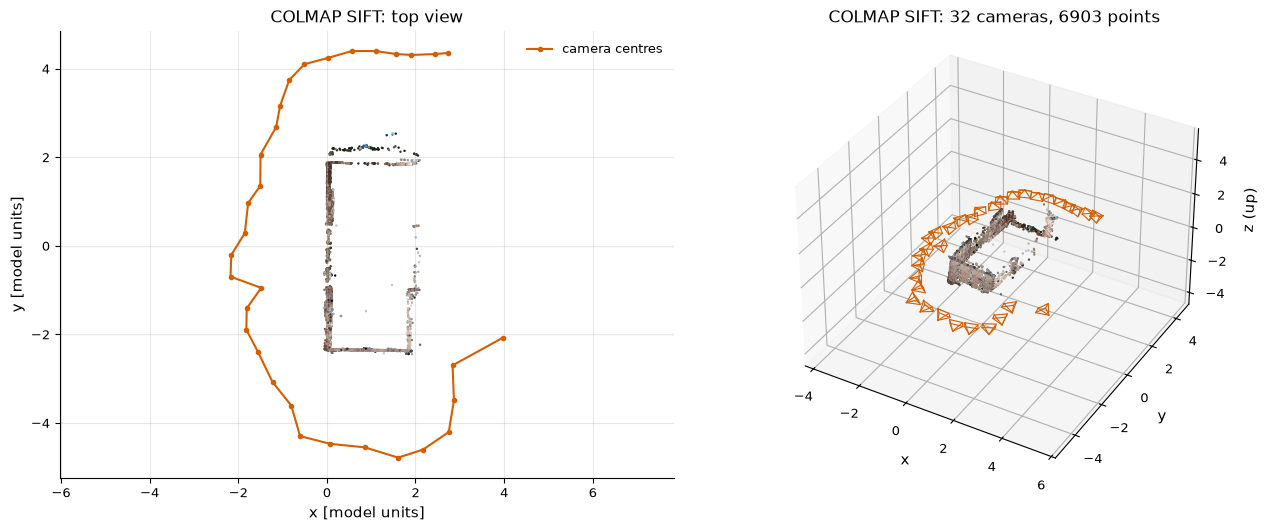

In [6]:
# --- Cameras and sparse points: top view and oblique 3D view ---
def plot_model(rec, title, axes):
    cams = dict(sorted(M.rec_cameras(rec).items()))  # capture order (file names)
    xyz, rgb, err, tl = M.rec_points(rec)
    R_up = M.gravity_align(cams)
    P = xyz @ R_up.T
    C = np.array([R_up @ c["T_wc"][:3, 3] for c in cams.values()])
    lo, hi = np.percentile(P, 2, axis=0), np.percentile(P, 98, axis=0)  # hide far outliers
    keep = np.all((P > lo - 0.1 * (hi - lo)) & (P < hi + 0.1 * (hi - lo)), axis=1)
    poses = []
    for c in cams.values():
        T = c["T_wc"].copy()
        T[:3, :3], T[:3, 3] = R_up @ T[:3, :3], R_up @ T[:3, 3]
        poses.append(T)
    k0 = next(iter(cams.values()))
    ax2d, ax3d = axes
    ax2d.scatter(P[keep, 0], P[keep, 1], s=0.5, c=rgb[keep] / 255.0)
    ax2d.plot(C[:, 0], C[:, 1], "o-", ms=3, color=viz.color(5, unit=True), label="camera centres")
    ax2d.set(xlabel="x [model units]", ylabel="y [model units]", title=f"{title}: top view")
    ax2d.set_aspect("equal", adjustable="datalim")
    ax2d.legend()
    ax3d.scatter(*P[keep].T, s=0.4, c=rgb[keep] / 255.0, depthshade=False)
    viz.plot_camera_frustums(ax3d, np.stack(poses), k0["K"], k0["width"], k0["height"],
                             scale=0.4, color_rgb=viz.color(5, unit=True))
    ax3d.view_init(elev=35, azim=-60)
    viz.set_axes_equal(ax3d)
    ax3d.set(xlabel="x", ylabel="y", zlabel="z (up)", title=f"{title}: {len(cams)} cameras, {keep.sum()} points")

fig = plt.figure(figsize=(13, 5.2))
plot_model(rec_sift, "COLMAP SIFT", [fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2, projection="3d")])
viz.savefig(fig, PROJECT, "sfm_sift_model")
plt.show()

**Track length** (number of images observing a point) and **reprojection error** describe
the internal quality of the model: long tracks constrain points (and cameras) well; the mean
reprojection error after bundle adjustment shows how *self-consistent* everything is.

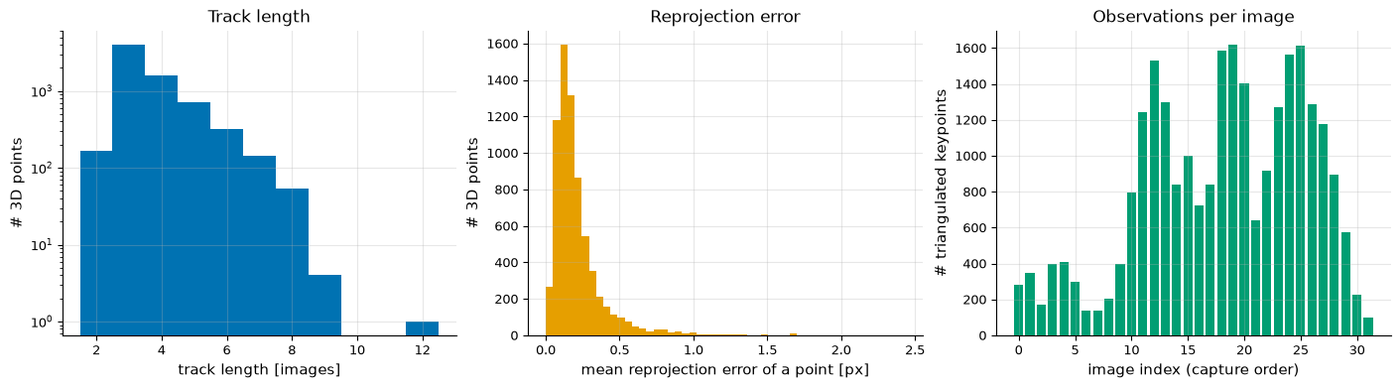

In [7]:
# --- Track-length and reprojection-error distributions, observations per image ---
xyz_s, rgb_s, err_s, tl_s = M.rec_points(rec_sift)
obs_per_image = sorted((img.name, img.num_points3D) for img in rec_sift.images.values() if img.has_pose)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(tl_s, bins=np.arange(2, tl_s.max() + 2) - 0.5, color=viz.color(0, unit=True))
ax[0].set(xlabel="track length [images]", ylabel="# 3D points", yscale="log", title="Track length")
ax[1].hist(err_s, bins=50, color=viz.color(1, unit=True))
ax[1].set(xlabel="mean reprojection error of a point [px]", ylabel="# 3D points", title="Reprojection error")
ax[2].bar(range(len(obs_per_image)), [n for _, n in obs_per_image], color=viz.color(2, unit=True))
ax[2].set(xlabel="image index (capture order)", ylabel="# triangulated keypoints", title="Observations per image")
plt.show()

## 4. DISK + LightGlue matches inside COLMAP

COLMAP's mapper does not care where correspondences come from. To use learned matches we:

1. create the database and register the images (`import_images`, one shared camera);
2. write each image's keypoints (`Database.write_keypoints`). **Pixel convention:** COLMAP
   puts the centre of the top-left pixel at (0.5, 0.5), OpenCV/kornia at (0, 0), so we add
   0.5 px; forgetting this biases the principal point by half a pixel;
3. write the raw LightGlue matches of every pair (`write_matches`) and a pair list;
4. let COLMAP verify them (`verify_matches`: RANSAC on F/E/H as before) and map.

DISK runs with 2048 keypoints per image (fp16); LightGlue matches all 496 pairs. The
keypoints and matches are kept in memory so that section 7 can re-use them.

In [8]:
# --- DISK + LightGlue (all pairs) -> COLMAP database -> verification -> incremental mapping ---
dl = M.DiskLightGlue(device=device, max_keypoints=2048, fp16=True)
lg_dir = OUT / "disk_lightglue"
with cvlab.device.track_vram() as mem:
    kps_lg, matches_lg, t_lg = M.disk_lightglue_match(dl, IMAGE_DIR, names)  # all 496 pairs
rec_lg, t_col = M.colmap_import_matches_sfm(IMAGE_DIR, names, lg_dir, kps_lg, matches_lg)
t_lg.update(t_col)
stats_lg = M.reconstruction_stats(rec_lg, len(names))
db_stats_lg = M.database_stats(lg_dir / "database.db")
print({k: round(v, 1) for k, v in t_lg.items()}, f"| peak VRAM {mem.peak_mb:.0f} MiB")
print(db_stats_lg)
print(stats_lg)
cam_lg = next(iter(rec_lg.cameras.values()))
print(f"self-calibrated f = {cam_lg.params[0]:.1f} px, k = {cam_lg.params[3]:.4f}")

{'features_s': 2.6, 'matching_s': 5.9, 'import_s': 0.2, 'verification_s': 2.1, 'mapping_s': 7.9} | peak VRAM 1238 MiB
{'num_images': 32, 'num_keypoints': 65536, 'num_matched_pairs': 496, 'num_verified_pairs': 496, 'num_matches': 100289, 'num_inlier_matches': 88539}
SfmStats(num_images_input=32, num_reg_images=32, num_points3D=9446, mean_track_length=4.111264027101418, mean_observations_per_image=1213.59375, mean_reprojection_error=0.5675621543749557)
self-calibrated f = 854.7 px, k = -0.0224


By the usual internal measures this looks like a success: every image is registered, there
are more points with longer tracks, and the reprojection error is below one pixel (higher than
SIFT's, as expected for keypoints on the integer pixel grid). The model and its view graph
tell a different story. Compare the top view with SIFT's, and notice how many *far-apart*
image pairs now have verified matches.

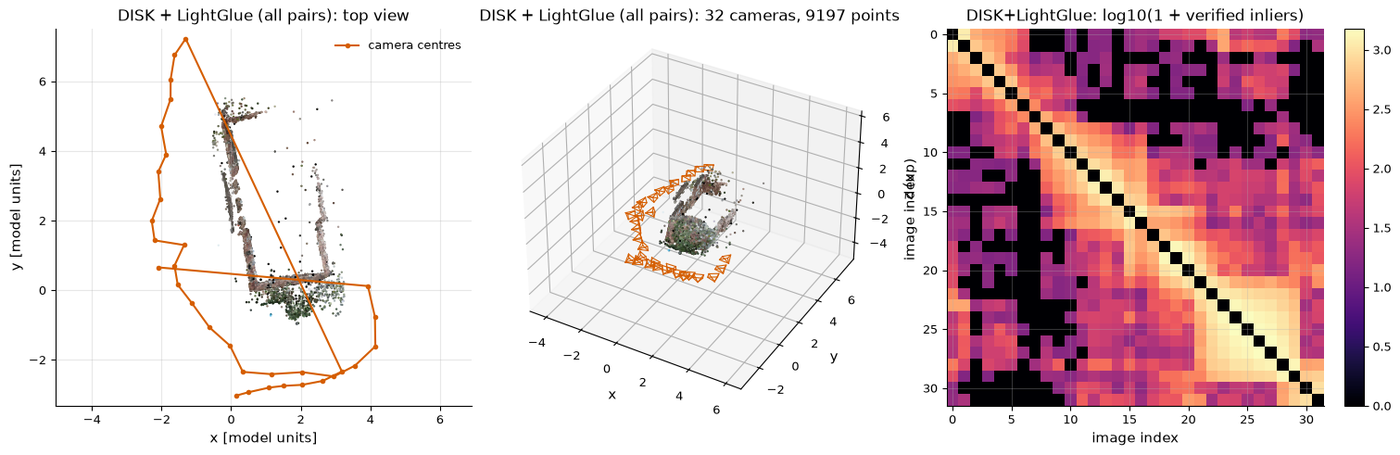

387 of 496 pairs have verified inlier matches (SIFT: 129)


In [9]:
# --- Plot the DISK + LightGlue model next to its view graph ---
G_lg = M.view_graph(lg_dir / "database.db", names)
fig = plt.figure(figsize=(15, 4.8))
plot_model(rec_lg, "DISK + LightGlue (all pairs)", [fig.add_subplot(1, 3, 1), fig.add_subplot(1, 3, 2, projection="3d")])
ax = fig.add_subplot(1, 3, 3)
im = ax.imshow(np.log10(1 + G_lg), cmap="magma")
ax.set(xlabel="image index", ylabel="image index", title="DISK+LightGlue: log10(1 + verified inliers)")
fig.colorbar(im, ax=ax)
viz.savefig(fig, PROJECT, "sfm_disk_lightglue_model")
plt.show()
print(f"{(G_lg > 0).sum() // 2} of {len(names) * (len(names) - 1) // 2} pairs have verified inlier matches "
      f"(SIFT: {(G_sift > 0).sum() // 2})")

## 5. Accuracy against the reference model

The dataset ships a COLMAP model built from the full-resolution (3072x2304) images of all
128 photos. It is not ground truth, but it is much better constrained than our 32-image,
1024 px models, so we use it as a reference. SfM is only defined up to a similarity
transform (scale, rotation, translation), so we first align our camera centres to the
reference with a **Sim(3) Umeyama** fit (`cvlab.geometry.umeyama_alignment`) and then compare:

* **rotation error**: the angle of $R_\text{ref}^\top\,(R_\text{align} R_\text{est})$ per camera;
* **centre error** after alignment, expressed relative to the median distance between
  consecutive cameras of the subset (the reference units are arbitrary).

In [10]:
# --- Compare both reconstructions with the reference model (Sim(3)-aligned) ---
ref = M.load_reference_cameras(scale_to_width=1024)
ref_f = next(iter(ref.values()))["K"][0, 0]

def accuracy_row(name, rec, subset):
    # Registration + accuracy of one model against the reference (Sim(3)-aligned camera centres).
    C_ref_seq = np.array([ref[n]["T_wc"][:3, 3] for n in subset])
    spacing = np.median(np.linalg.norm(np.diff(C_ref_seq, axis=0), axis=1))  # median camera spacing
    c = M.compare_to_reference(M.rec_cameras(rec), ref)
    f_est = next(iter(rec.cameras.values())).params[0]
    return {"method": name, "registered": int(rec.num_reg_images()),
            "median rot err [deg]": float(np.median(c["rot_err_deg"])),
            "max rot err [deg]": float(np.max(c["rot_err_deg"])),
            "median centre err [% spacing]": float(100 * np.median(c["center_err"]) / spacing),
            "max centre err [% spacing]": float(100 * np.max(c["center_err"]) / spacing),
            "focal error vs reference [%]": float(100 * (f_est - ref_f) / ref_f)}

acc_rows = [accuracy_row("COLMAP SIFT (all pairs)", rec_sift, names),
            accuracy_row("DISK + LightGlue (all pairs)", rec_lg, names)]
print(f"reference focal length at 1024 px: {ref_f:.1f} px")
pd.DataFrame(acc_rows).round(3)

reference focal length at 1024 px: 853.2 px

,method,registered,median rot err [deg],max rot err [deg],median centre err [% spacing],max centre err [% spacing],focal error vs reference [%]
0,COLMAP SIFT (all pairs),32,0.356,1.388,3.182,10.970,0.516
1,DISK + LightGlue (all pairs),32,26.255,158.978,524.153,1033.635,0.169


The SIFT model agrees with the reference to a fraction of a degree and a few percent of the
camera spacing. The DISK + LightGlue model, with every image registered and a sub-pixel
reprojection error, is **wrong**: some cameras are off by tens of degrees and the centres by
several camera spacings. The focal length is still estimated well, which shows that the
damage is in the global arrangement of the cameras, not in the local geometry.

## 6. What went wrong: look-alike facades

The reference model tells us which image pairs really overlap: two images that observe at
least one common reference 3D point are **co-visible**. A verified pair with *zero*
co-visibility is almost certainly a false match: two different parts of the building that
look the same. Such *doppelgangers* are common in architecture (symmetric facades, repeated
windows) and in robotics (corridors, shelves, parking garages).

In [11]:
# --- Verified pairs vs co-visibility in the reference model ---
cov = M.reference_covisibility(names)  # number of shared reference 3D points per pair
iu = np.triu_indices(len(names), 1)
dop_rows = []
for name, G in [("COLMAP SIFT", G_sift), ("DISK + LightGlue", G_lg)]:
    g, c = G[iu], cov[iu]
    false = (g > 0) & (c == 0)
    dop_rows.append({"method": name, "pairs with inliers": int((g > 0).sum()),
                     "co-visible pairs (reference)": int((c > 0).sum()),
                     "inlier pairs NOT co-visible": int(false.sum()),
                     "median inliers of those": float(np.median(g[false])) if false.any() else 0.0,
                     "max inliers of those": int(g[false].max()) if false.any() else 0,
                     "co-visible pairs without inliers": int(((g == 0) & (c > 0)).sum())})
dop_df = pd.DataFrame(dop_rows)
dop_df

,method,pairs with inliers,co-visible pairs (reference),inlier pairs NOT co-visible,median inliers of those,max inliers of those,co-visible pairs without inliers
0,COLMAP SIFT,129,170,19,18.0,24,60
1,DISK + LightGlue,387,170,222,39.0,392,5


SIFT's ratio test rejects a match when the second-best candidate is almost as similar,
which is exactly the situation on a facade with repeated windows. Its false pairs have at
most a few dozen inliers. LightGlue reasons about the *whole set* of keypoints jointly: when
two facades look alike, it matches them consistently, and the resulting correspondences fit
an epipolar geometry or a homography perfectly, so COLMAP's verification accepts them with a
high inlier ratio. Here is the false pair with the most verified inliers:

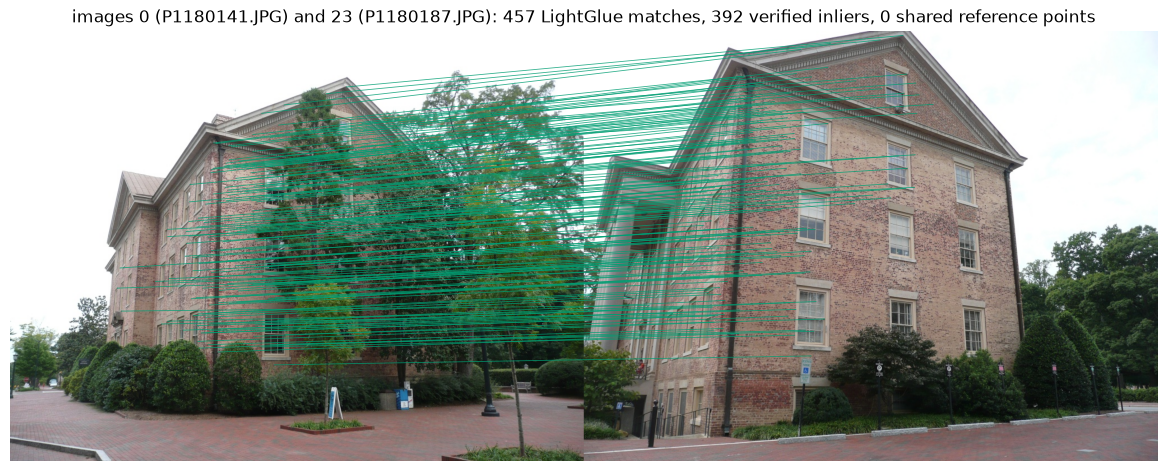

In [12]:
# --- The worst doppelganger pair: many verified LightGlue matches, no common reference point ---
g_false = np.where((G_lg[iu] > 0) & (cov[iu] == 0), G_lg[iu], -1)
k = int(np.argmax(g_false))
i, j = int(iu[0][k]), int(iu[1][k])
a, b = names[i], names[j]
mm = matches_lg[(a, b)]
fig, ax = plt.subplots(figsize=(12, 4.6))
M.draw_matches(ax, read_image(IMAGE_DIR / a), read_image(IMAGE_DIR / b),
               kps_lg[a][mm[:, 0]], kps_lg[b][mm[:, 1]], max_lines=150)
ax.set_title(f"images {i} ({a}) and {j} ({b}): {len(mm)} LightGlue matches, {G_lg[i, j]} verified "
             f"inliers, {cov[i, j]} shared reference points")
viz.savefig(fig, PROJECT, "sfm_doppelganger_pair")
plt.show()

## 7. A pairing prior for ordered captures

The photos were taken while walking, so true overlaps are between images close in the
sequence. Matching only pairs at most $w$ images apart is what COLMAP's *sequential* matcher
does for video. It removes most doppelganger pairs, which join images far apart in the
walk, and it also reduces matching cost from $O(N^2)$ to $O(Nw)$ pairs.

We re-use the DISK keypoints and LightGlue matches from section 4, keep only the pairs within
the window, and re-run verification + mapping for $w \in \{3, 5, 8\}$. The column "false
pairs kept" counts kept pairs that had verified inliers in section 4 but no co-visibility in
the reference.

**One run is not enough.** COLMAP's multi-threaded verification and mapping are not
bit-reproducible: even with a fixed seed, identical inputs can produce different models.
Usually the differences are tiny, but when a configuration sits close to a failure mode
(here: a few wrong or weak links in the view graph) they decide between a correct and a
folded reconstruction. We therefore run every window three times (RANSAC and mapper seeds
0, 1, 2) and count the runs that register all 32 images *and* agree with the reference
(median rotation error below 1°).

In [13]:
# --- Re-map with sequential pairing windows w = 3, 5, 8, three runs each (same features and matches) ---
# Only COLMAP's verification + mapping is repeated; the DISK keypoints and LightGlue matches
# from section 4 are re-used, so the spread comes from COLMAP's randomness and thread order.
WINDOWS, SEEDS, GOOD_DEG = (3, 5, 8), (0, 1, 2), 1.0
win_rows, win_recs = [], {}
for w in WINDOWS:
    sel = {p: mm for p, mm in matches_lg.items() if names.index(p[1]) - names.index(p[0]) <= w}
    n_false = sum(int(G_lg[names.index(p), names.index(q)] > 0 and cov[names.index(p), names.index(q)] == 0)
                  for p, q in sel)
    for s in SEEDS:
        # Seed 0 goes to the folder that run_sfm.py also uses; the repeats to window_runs/.
        work = OUT / f"disk_lightglue_window{w}" if s == 0 else OUT / "window_runs" / f"w{w}_seed{s}"
        t0 = time.perf_counter()
        rec_w, _ = M.colmap_import_matches_sfm(IMAGE_DIR, names, work, kps_lg, sel, random_seed=s)
        dt = time.perf_counter() - t0
        win_recs[(w, s)] = rec_w
        st = M.reconstruction_stats(rec_w, len(names))
        acc = accuracy_row(f"DISK + LightGlue (w={w})", rec_w, names)
        win_rows.append({"window w": w, "seed": s, "pairs": len(sel), "false pairs kept": n_false,
                         **{k: acc[k] for k in ("registered", "median rot err [deg]", "max rot err [deg]",
                                                "median centre err [% spacing]")},
                         "points": st.num_points3D, "reproj err [px]": st.mean_reprojection_error,
                         "verify + map [s]": dt})
win_df = pd.DataFrame(win_rows)
win_df["all registered, < 1 deg"] = (win_df["registered"] == len(names)) & (win_df["median rot err [deg]"] < GOOD_DEG)
display(win_df.round(3))
# One line per window: how many of the runs agree with the reference, best and worst run.
win_summary = (win_df.groupby("window w")
               .agg(**{"pairs": ("pairs", "first"), "false pairs kept": ("false pairs kept", "first"),
                       "runs": ("seed", "size"),
                       "runs OK": ("all registered, < 1 deg", "sum"),
                       "best median rot err [deg]": ("median rot err [deg]", "min"),
                       "worst median rot err [deg]": ("median rot err [deg]", "max")})
               .reset_index())
win_summary.round(3)

,window w,seed,pairs,false pairs kept,registered,median rot err [deg],max rot err [deg],median centre err [% spacing],points,reproj err [px],verify + map [s],"all registered, < 1 deg"
0,3,0,90,0,32,3.238,42.036,34.198,7749,0.535,33.464,False
1,3,1,90,0,32,0.275,0.469,2.152,8630,0.531,4.222,True
2,3,2,90,0,32,2.128,9.371,21.878,8524,0.524,16.819,False
3,5,0,145,3,32,0.251,0.401,2.025,8978,0.548,4.960,True
4,5,1,145,3,31,2.983,47.654,31.573,7551,0.491,26.351,False
5,5,2,145,3,32,5.515,28.451,55.561,8453,0.544,23.096,False
6,8,0,220,38,32,0.300,0.456,2.221,9209,0.551,8.168,True
7,8,1,220,38,32,0.966,3.012,9.097,9219,0.552,9.807,True
8,8,2,220,38,32,0.305,0.424,2.241,9210,0.551,8.015,True


,window w,pairs,false pairs kept,runs,runs OK,best median rot err [deg],worst median rot err [deg]
0,3,90,0,3,1,0.275,3.238
1,5,145,3,3,1,0.251,5.515
2,8,220,38,3,3,0.300,0.966


The camera centres make the difference visible. Below, each estimate is aligned to the
reference with Sim(3) and drawn in a top view of the reference frame; red segments connect
each estimated camera to its reference position. The panels show SIFT, DISK + LightGlue on
all pairs, the *worst* of the three $w = 3$ runs and the first $w = 8$ run; the last panel
shows the median rotation error of every run.

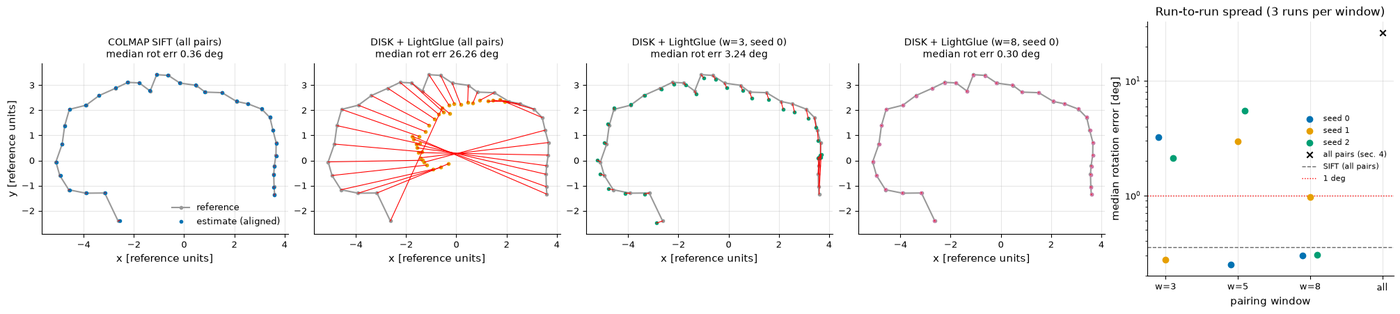

In [14]:
# --- Aligned camera centres vs reference, and the run-to-run spread of every window ---
R_up_ref = M.gravity_align({n: ref[n] for n in names})
seed_w3 = int(win_df[win_df["window w"] == 3].sort_values("median rot err [deg]").iloc[-1]["seed"])
models = [("COLMAP SIFT (all pairs)", rec_sift), ("DISK + LightGlue (all pairs)", rec_lg),
          (f"DISK + LightGlue (w=3, seed {seed_w3})", win_recs[(3, seed_w3)]),
          ("DISK + LightGlue (w=8, seed 0)", win_recs[(8, 0)])]
cmps = [M.compare_to_reference(M.rec_cameras(rec), ref) for _, rec in models]
allp = np.concatenate([np.concatenate([c["C_ref"], c["C_est_aligned"]]) @ R_up_ref.T for c in cmps])
lo, hi = allp[:, :2].min(axis=0), allp[:, :2].max(axis=0)
pad = 0.05 * (hi - lo).max()
fig, axes = plt.subplots(1, len(models) + 1, figsize=(4.0 * (len(models) + 1), 4.4))
for k, (ax, (title, _), c) in enumerate(zip(axes, models, cmps)):
    Cr, Ce = c["C_ref"] @ R_up_ref.T, c["C_est_aligned"] @ R_up_ref.T  # top view of the reference
    ax.plot(Cr[:, 0], Cr[:, 1], "o-", ms=3, color="0.6", label="reference")
    ax.plot(Ce[:, 0], Ce[:, 1], "o", ms=3, color=viz.color(k, unit=True), label="estimate (aligned)")
    for p, q in zip(Cr, Ce):
        ax.plot([p[0], q[0]], [p[1], q[1]], color="r", lw=0.8)
    ax.set_title(f"{title}\nmedian rot err {np.median(c['rot_err_deg']):.2f} deg", fontsize=10)
    ax.set_xlabel("x [reference units]")
    ax.set(xlim=(lo[0] - pad, hi[0] + pad), ylim=(lo[1] - pad, hi[1] + pad))
    ax.set_aspect("equal", adjustable="box")  # same limits and scale in every panel
axes[0].set_ylabel("y [reference units]")
axes[0].legend(loc="best")
# Last panel: median rotation error of every run (log scale), per pairing strategy.
ax = axes[-1]
xpos = {w: i for i, w in enumerate(WINDOWS)} | {"all": len(WINDOWS)}
for k, s in enumerate(SEEDS):
    sub = win_df[win_df.seed == s]
    ax.scatter([xpos[w] + 0.1 * (k - 1) for w in sub["window w"]], sub["median rot err [deg]"],
               color=viz.color(k, unit=True), label=f"seed {s}", zorder=3)
ax.scatter([xpos["all"]], [acc_rows[1]["median rot err [deg]"]], color="k", marker="x", label="all pairs (sec. 4)")
ax.axhline(acc_rows[0]["median rot err [deg]"], color="0.4", ls="--", lw=1, label="SIFT (all pairs)")
ax.axhline(GOOD_DEG, color="r", ls=":", lw=1, label="1 deg")
ax.set_xticks(list(xpos.values()), [f"w={w}" for w in WINDOWS] + ["all"])
ax.set(yscale="log", xlabel="pairing window", ylabel="median rotation error [deg]",
       title="Run-to-run spread (3 runs per window)")
ax.legend(fontsize=8, loc="center right")
viz.savefig(fig, PROJECT, "sfm_vs_reference")
plt.show()

Restricting the pairs helps, but small windows are not reliable. With $w = 3$ and $w = 5$
only one of the three runs gave an accurate model; the other runs ended with median rotation
errors of 2-6° and worst cameras off by 9° to 48°, although $w = 3$ keeps **no** false pair
at all. Removing the doppelgangers is therefore not enough: with only three neighbours per
image the view graph is a thin chain, and small differences in which pairs pass verification
and in which order images are registered decide whether errors accumulate into a bent or
folded model. The wider window $w = 8$ keeps 38 false pairs but adds many correct, long
constraints that outvote them: all three runs registered every image with a median rotation
error below 1° (0.30° and 0.31° for seeds 0 and 2; 0.97° with a worst camera at 3.0° for
seed 1, so even this setting is not perfectly stable).

A pairing prior is a useful *mitigation* for ordered captures, not a guarantee. Robust systems
add explicit checks: loop-consistency of relative rotations (Zach et al., CVPR 2010, with
images by the same author as this dataset), learned doppelganger classifiers (Cai et al.,
ICCV 2023), or external sensors (wheel odometry, IMU, GPS) that rule out impossible
relative poses.

## 8. Stress test: a sparser image set

Every fourth photo of the **whole** 128-image loop (again 32 images) doubles the distance
between neighbours and includes a gap in the walk (between photos 84 and 85 the reference
camera centre jumps by about 26 times the typical spacing). We run SIFT and DISK + LightGlue
on all pairs, plus DISK + LightGlue with the windows $w = 3$ and $w = 8$, and score everything
against the reference (one run each).

In [15]:
# --- Same pipelines on every 4th image of the full loop, scored against the reference ---
names_wide = all_names[::4]
rec_sift_w, t_sift_w = M.colmap_sift_sfm(IMAGE_DIR, names_wide, OUT / "wide_sift")
kps_w, matches_w, t_lg_w = M.disk_lightglue_match(dl, IMAGE_DIR, names_wide)
rec_lg_w, t_c = M.colmap_import_matches_sfm(IMAGE_DIR, names_wide, OUT / "wide_disk_lightglue", kps_w, matches_w)
t_lg_w.update(t_c)
runs_wide = [("COLMAP SIFT (all pairs)", rec_sift_w, "wide_sift", t_sift_w),
             ("DISK + LightGlue (all pairs)", rec_lg_w, "wide_disk_lightglue", t_lg_w)]
for w in (3, 8):
    sel_w = {p: mm for p, mm in matches_w.items() if names_wide.index(p[1]) - names_wide.index(p[0]) <= w}
    rec_ww, t_ww = M.colmap_import_matches_sfm(IMAGE_DIR, names_wide, OUT / f"wide_disk_lightglue_window{w}",
                                               kps_w, sel_w)
    runs_wide.append((f"DISK + LightGlue (w={w})", rec_ww, f"wide_disk_lightglue_window{w}", t_ww))
wide_rows = []
for name, rec, sub, tm in runs_wide:
    n_models = len(list((OUT / sub / "sparse").iterdir()))
    row = accuracy_row(name, rec, names_wide)
    row.pop("focal error vs reference [%]")
    wide_rows.append({**row, "models": n_models, "points": rec.num_points3D(),
                      "reproj err [px]": rec.compute_mean_reprojection_error(),
                      "time [s]": sum(tm.values())})
wide_df = pd.DataFrame(wide_rows)
wide_df.round(3)

,method,registered,median rot err [deg],max rot err [deg],median centre err [% spacing],max centre err [% spacing],models,points,reproj err [px],time [s]
0,COLMAP SIFT (all pairs),22,0.260,0.442,0.625,1.814,1,4787,0.221,20.321
1,DISK + LightGlue (all pairs),32,1.092,180.000,134.133,425.442,1,9450,0.597,19.855
2,DISK + LightGlue (w=3),25,36.390,130.958,160.326,448.077,2,4880,0.571,7.480
3,DISK + LightGlue (w=8),28,11.308,171.674,224.806,507.357,2,6994,0.514,13.771


On the sparser set COLMAP SIFT registers only 22 of the 32 images, but those 22 agree with
the reference (median rotation error 0.26°). DISK + LightGlue on all pairs registers all 32
images and its median rotation error looks harmless (1.1°), yet some cameras are rotated by
180° and the median centre error is 134 % of the camera spacing: part of the loop is folded
onto the other side of the building. Both windows split the images into two models whose
largest one is wrong (25 images at 36° with $w = 3$, 28 images at 11° with $w = 8$). With
every fourth photo, a window of 8 spans 32 original photos, a quarter of the loop, so it no
longer separates the look-alike facades, while $w = 3$ most likely leaves too few links across
the gap in the walk. For a robot, a partial but correct map (SIFT here) is much easier to detect and
extend than a complete but folded one.

## 9. Export for reuse

`incremental_mapping` already wrote binary COLMAP models (`cameras.bin`, `images.bin`,
`points3D.bin`) to `runs/09_multiview_geometry/south_building/<method>/sparse/0`, next to the
database. We export the coloured sparse points of SIFT and of DISK + LightGlue with $w = 8$
(seed 0) as PLY files (`outputs/`) and write the image lists. Projects 10 and 11 load the
cameras with `pycolmap.Reconstruction(path)`; the SIFT model is the recommended one.
`scripts/run_sfm.py` rebuilds both models from the command line with the same settings.

In [16]:
# --- Export PLY point clouds and the image list (gitignored outputs) ---
out_dir = outputs_dir(PROJECT, create=True)
exports = {}
for name, rec, d in [("sift", rec_sift, sift_dir),
                     ("disk_lightglue_window8", win_recs[(8, 0)], OUT / "disk_lightglue_window8")]:
    ply = out_dir / f"south_building_{name}_sparse.ply"
    rec.export_PLY(ply)
    (d / "image_list.txt").write_text("\n".join(names) + "\n")
    model_dirs = sorted(p.name for p in (d / "sparse").iterdir())
    exports[name] = {"model_dirs": model_dirs, "ply": str(ply.relative_to(repo_root())),
                     "ply_kb": ply.stat().st_size / 1024}
    print(f"{name:24s} models {model_dirs} | {ply.relative_to(repo_root())} ({ply.stat().st_size / 1024:.0f} KiB)")

sift                     models ['0'] | outputs/09_multiview_geometry/south_building_sift_sparse.ply (104 KiB)
disk_lightglue_window8   models ['0'] | outputs/09_multiview_geometry/south_building_disk_lightglue_window8_sparse.ply (135 KiB)


## Results

All numbers below were measured in this notebook (COLMAP 4.2 on the CPU, DISK + LightGlue on
the RTX 5060 Laptop GPU, 8 GB). "w=8" is DISK + LightGlue restricted to pairs at most eight
images apart (first of the three runs of section 7).

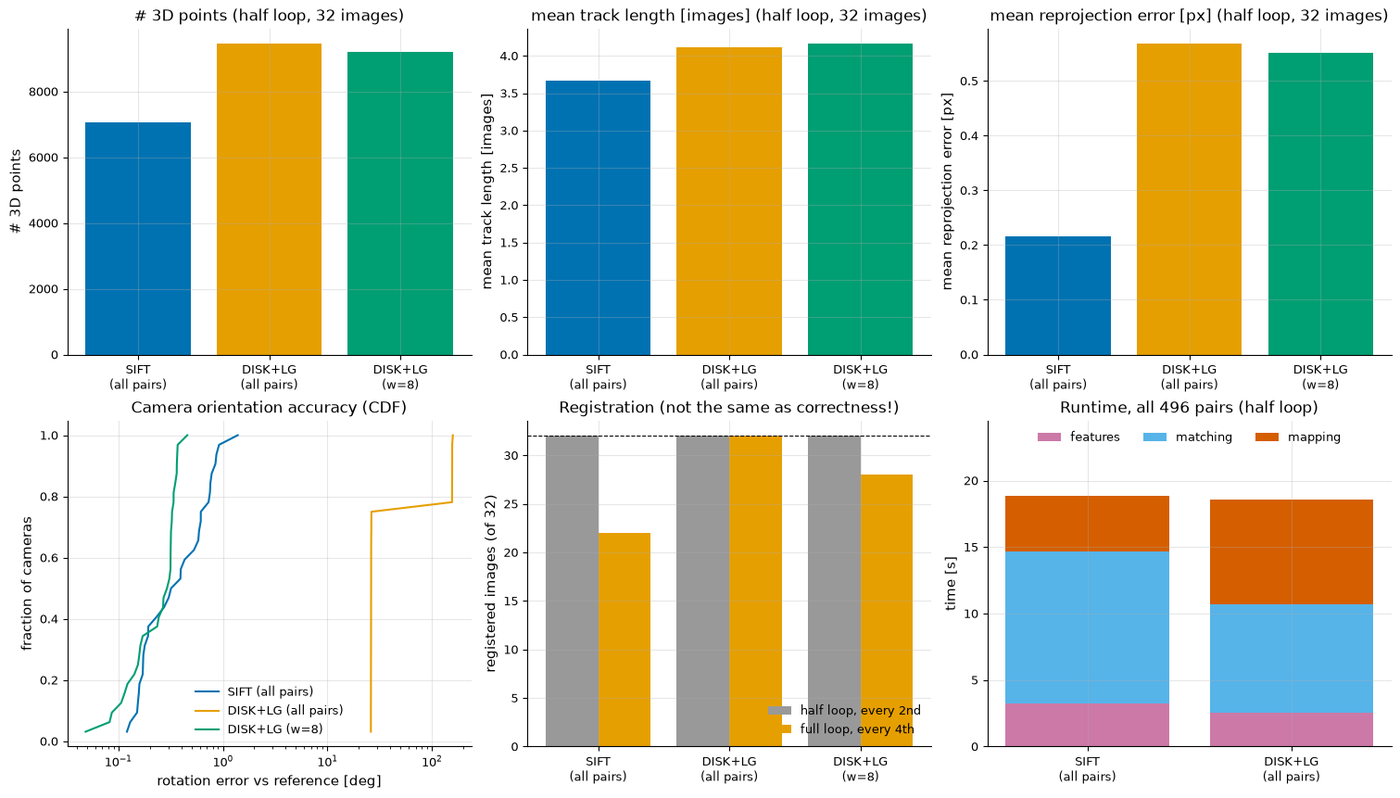

In [17]:
# --- Summary figure: model statistics, accuracy vs reference, registration, runtime ---
rec_w8 = win_recs[(8, 0)]
stats_w8 = M.reconstruction_stats(rec_w8, len(names))
summary = pd.DataFrame([
    {"method": "COLMAP SIFT (all pairs)", **stats_sift.as_dict(),
     "features [s]": t_feat, "matching [s]": t_match, "mapping [s]": t_map},
    {"method": "DISK + LightGlue (all pairs)", **stats_lg.as_dict(), "features [s]": t_lg["features_s"],
     "matching [s]": t_lg["matching_s"] + t_lg["import_s"] + t_lg["verification_s"],
     "mapping [s]": t_lg["mapping_s"]},
    {"method": "DISK + LightGlue (w=8)", **stats_w8.as_dict()}])
labels = ["SIFT\n(all pairs)", "DISK+LG\n(all pairs)", "DISK+LG\n(w=8)"]
cols = [viz.color(k, unit=True) for k in range(3)]
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
for a, key, label in [(ax[0, 0], "num_points3D", "# 3D points"),
                      (ax[0, 1], "mean_track_length", "mean track length [images]"),
                      (ax[0, 2], "mean_reprojection_error", "mean reprojection error [px]")]:
    a.bar(labels, summary[key], color=cols)
    a.set(ylabel=label, title=label + " (half loop, 32 images)")
for k, rec in enumerate([rec_sift, rec_lg, rec_w8]):
    e = np.sort(M.compare_to_reference(M.rec_cameras(rec), ref)["rot_err_deg"])
    ax[1, 0].plot(e, np.arange(1, len(e) + 1) / len(e), color=cols[k], label=labels[k].replace("\n", " "))
ax[1, 0].set(xscale="log", xlabel="rotation error vs reference [deg]", ylabel="fraction of cameras",
             title="Camera orientation accuracy (CDF)")
ax[1, 0].legend()
xs = np.arange(3)
half_reg = [stats_sift.num_reg_images, stats_lg.num_reg_images, stats_w8.num_reg_images]
wide_reg = wide_df.set_index("method").loc[["COLMAP SIFT (all pairs)", "DISK + LightGlue (all pairs)",
                                            "DISK + LightGlue (w=8)"], "registered"].values
ax[1, 1].bar(xs - 0.2, half_reg, 0.4, label="half loop, every 2nd", color="0.6")
ax[1, 1].bar(xs + 0.2, wide_reg, 0.4, label="full loop, every 4th", color=cols[1])
ax[1, 1].axhline(32, color="k", lw=0.8, ls="--")
ax[1, 1].set_xticks(xs, labels)
ax[1, 1].set(ylabel="registered images (of 32)", title="Registration (not the same as correctness!)")
ax[1, 1].legend(loc="lower right")
bottom = np.zeros(2)
for k, key in enumerate(["features [s]", "matching [s]", "mapping [s]"]):
    vals = summary[key].values[:2]
    ax[1, 2].bar(labels[:2], vals, bottom=bottom, label=key.replace(" [s]", ""), color=viz.color(k + 3, unit=True))
    bottom += vals
ax[1, 2].set(ylabel="time [s]", title="Runtime, all 496 pairs (half loop)", ylim=(0, 1.3 * bottom.max()))
ax[1, 2].legend(loc="upper center", ncol=3)  # above the bars, so no patch hides behind a bar
viz.savefig(fig, PROJECT, "sfm_summary")
plt.show()

The tables: model statistics with timings, accuracy against the reference of the three
half-loop models above, the run-to-run summary of the pairing windows (section 7) and the
stress test (section 8). Everything is also written to `results/nb04_sfm.json`.

In [18]:
# --- Summary tables (saved to results/nb04_sfm.json) ---
acc_all = pd.DataFrame(acc_rows + [accuracy_row("DISK + LightGlue (w=8)", rec_w8, names)])
save_json({"subset": names, "sift": {**stats_sift.as_dict(), "db": db_stats_sift,
                                     "times_s": {"features": t_feat, "matching": t_match, "mapping": t_map}},
           "disk_lightglue": {**stats_lg.as_dict(), "db": db_stats_lg, "times_s": t_lg,
                              "peak_vram_mb": mem.peak_mb},
           "disk_lightglue_window8": stats_w8.as_dict(),
           "accuracy_vs_reference": acc_all.to_dict("records"), "doppelganger_pairs": dop_rows,
           "window_runs": win_df.to_dict("records"), "window_summary": win_summary.to_dict("records"),
           "wide": wide_rows, "exports": exports, "reference_focal_px": ref_f}, RESULTS_DIR / "nb04_sfm.json")
display(summary.round(3))
display(acc_all.round(3))
display(win_summary.round(3))
display(wide_df.round(3))

,method,num_images_input,num_reg_images,num_points3D,mean_track_length,mean_observations_per_image,mean_reprojection_error,features [s],matching [s],mapping [s]
0,COLMAP SIFT (all pairs),32,32,7071,3.668,810.406,0.216,3.270,11.394,4.202
1,DISK + LightGlue (all pairs),32,32,9446,4.111,1213.594,0.568,2.552,8.133,7.905
2,DISK + LightGlue (w=8),32,32,9209,4.159,1196.969,0.551,NaN,NaN,NaN


,method,registered,median rot err [deg],max rot err [deg],median centre err [% spacing],max centre err [% spacing],focal error vs reference [%]
0,COLMAP SIFT (all pairs),32,0.356,1.388,3.182,10.970,0.516
1,DISK + LightGlue (all pairs),32,26.255,158.978,524.153,1033.635,0.169
2,DISK + LightGlue (w=8),32,0.300,0.456,2.221,4.725,-0.065


,window w,pairs,false pairs kept,runs,runs OK,best median rot err [deg],worst median rot err [deg]
0,3,90,0,3,1,0.275,3.238
1,5,145,3,3,1,0.251,5.515
2,8,220,38,3,3,0.300,0.966


,method,registered,median rot err [deg],max rot err [deg],median centre err [% spacing],max centre err [% spacing],models,points,reproj err [px],time [s]
0,COLMAP SIFT (all pairs),22,0.260,0.442,0.625,1.814,1,4787,0.221,20.321
1,DISK + LightGlue (all pairs),32,1.092,180.000,134.133,425.442,1,9450,0.597,19.855
2,DISK + LightGlue (w=3),25,36.390,130.958,160.326,448.077,2,4880,0.571,7.480
3,DISK + LightGlue (w=8),28,11.308,171.674,224.806,507.357,2,6994,0.514,13.771


**Takeaways**

* **Registration and reprojection error do not measure correctness.** Every half-loop model
  registered all 32 images with a sub-pixel mean reprojection error (0.22 px for SIFT,
  0.57 px for DISK + LightGlue), yet DISK + LightGlue on all pairs is folded: median rotation
  error 26.3° and camera centres off by 524 % of the camera spacing (median). Only an
  independent reference revealed it; on a robot, odometry or an IMU can play that role.
* **Look-alike structures beat strong matchers.** LightGlue produced verified matches for 222
  image pairs that share no reference point (up to 392 inliers for a single false pair);
  SIFT's ratio test let 19 through, with at most 24 inliers. The recall that wins on hard
  pairs in notebook 03 also produces confident false positives on repeated structure.
* **COLMAP SIFT is the safe default here**: median rotation error 0.36°, median centre error
  3.2 % of the camera spacing and a self-calibrated focal length within 0.52 % of the
  reference, in about 19 s on the CPU (3.3 s features, 11.4 s exhaustive matching +
  verification, 4.2 s mapping).
* **A pairing prior helps, but judge it over several runs.** DISK + LightGlue with $w = 8$
  gave accurate models in all three runs (0.30° median rotation error for the first run,
  with more points and longer tracks than SIFT: 9209 vs 7071 points, 4.16 vs 3.67 images per
  track), while $w = 3$ and $w = 5$ succeeded in one run of three each. COLMAP's
  multi-threaded verification and mapping are not bit-reproducible, so a single run can make
  a fragile configuration look fine, or a good one look broken.
* **Wider baselines expose every pipeline.** On every fourth photo of the full loop no DISK +
  LightGlue variant produced a correct model, while SIFT registered 22 of 32 images
  correctly. The pairing window has to match the capture density.
* **Cost.** For 32 images, DISK + LightGlue needs 2.6 s for features and 5.9 s to match all
  496 pairs on the GPU (peak 1238 MiB of VRAM); COLMAP verification and mapping run on the
  CPU in seconds. The expensive part of robust SfM is not computing the matches, it is
  deciding which of them to trust.

## Exercises

Solutions: `projects/09_multiview_geometry/solutions/solutions_04.py` (CPU).

**Exercise 1: camera models.** Re-run the SIFT pipeline with `PINHOLE` (no distortion),
`SIMPLE_RADIAL` and `OPENCV` (fx, fy, cx, cy, k1, k2, p1, p2). Compare the mean reprojection
error and the rotation error against the reference. Which model is justified here?

In [19]:
# --- Exercise 1: camera-model ablation (TODO) ---
# TODO: M.colmap_sift_sfm(IMAGE_DIR, names, OUT / f"ex1_{model}", camera_model=model) for each model,
#       then M.reconstruction_stats and M.compare_to_reference(M.rec_cameras(rec), ref).

**Exercise 2: sequential vs exhaustive matching.** For video-like captures,
`pycolmap.match_sequential` only matches each image with its next `overlap` neighbours
(plus optional loop detection). Run it with `SequentialPairingOptions(overlap=5)` on the
same 32 images with SIFT and compare matching time, number of matched pairs, registered
images and accuracy against the reference.

In [20]:
# --- Exercise 2: match_sequential with a small overlap (TODO) ---
# TODO: extract_features into a new database, then
#       pycolmap.match_sequential(db, pairing_options=pycolmap.SequentialPairingOptions(overlap=5))

**Exercise 3: multi-view triangulation by hand.** Take the 3D point of the SIFT model with
the longest track. Undistort its observations with the SIMPLE_RADIAL camera
(`camera.cam_from_img`), build the $2N \times 4$ DLT system from all $N$ views and solve it
with an SVD. Compare your point with COLMAP's (bundle-adjusted) `xyz` and with its
reprojection error in every view.

In [21]:
# --- Exercise 3: N-view DLT for the longest track (TODO) ---
# TODO: pid = max(rec_sift.points3D, key=lambda i: rec_sift.points3D[i].track.length())
#       for el in rec_sift.points3D[pid].track.elements: image, point2D_idx -> observation.